# 04 · Route-level detail on the full 6.4M-flight file
The sample is fine for national patterns but thin at route level (only 417 routes with 100+
sampled flights). Here the full file answers: **does carrier choice still matter on the same
route?** and **does time of day still matter for the same carrier on the same route?**

In [1]:
import sys
sys.path.insert(0, "../src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import prep, style
from style import INK, GREY, ACCENT, GOOD, BLUE, AMBER, PCT
style.use()
pd.set_option("display.width", 200, "display.max_columns", 60, "display.float_format", "{:.3f}".format)

f = pd.read_parquet(prep.PROCESSED / "flights_full.parquet")
s = pd.read_parquet(prep.PROCESSED / "flights_sample.parquet")
f["carrier_name"] = f.CARRIER.astype(str).map(prep.CARRIER_NAMES)
print(f"{len(f):,} flights, {f.route.nunique():,} routes")

6,398,056 flights, 5,785 routes


## 1. Does the 200k sample reproduce the population?

In [2]:
cmp = pd.DataFrame({"sample": s.groupby("CARRIER").disrupted.mean(), "population": f.groupby("CARRIER", observed=True).disrupted.mean()})
lo, hi = prep.wilson(s.groupby("CARRIER").disrupted.sum(), s.groupby("CARRIER").size())
cmp["sample_ci_lo"], cmp["sample_ci_hi"] = lo, hi
cmp["population_inside_ci"] = cmp.population.between(cmp.sample_ci_lo, cmp.sample_ci_hi)
cmp.loc["ALL"] = [s.disrupted.mean(), f.disrupted.mean(), *prep.wilson(s.disrupted.sum(), len(s)), None]
cmp.loc["ALL", "population_inside_ci"] = cmp.loc["ALL", "population"] >= cmp.loc["ALL", "sample_ci_lo"] and cmp.loc["ALL", "population"] <= cmp.loc["ALL", "sample_ci_hi"]
cmp.to_csv(prep.TABLES / "sample_vs_population.csv")
cmp

,sample,population,sample_ci_lo,sample_ci_hi,population_inside_ci
CARRIER,,,,,
AA,0.271,0.273,0.266,0.276,1.000
AS,0.238,0.242,0.229,0.248,1.000
B6,0.282,0.277,0.272,0.292,1.000
DL,0.205,0.209,0.201,0.210,1.000
MQ,0.235,0.230,0.226,0.243,1.000
OH,0.312,0.310,0.302,0.322,1.000
OO,0.219,0.221,0.214,0.224,1.000
UA,0.224,0.223,0.219,0.229,1.000
WN,0.224,0.222,0.220,0.228,1.000


## 2. Same route, different carrier
For every route x time-band x month cell with at least two carriers, compare each carrier with
the other carriers in that cell. This strips out the "that airline just flies to bad airports
at bad times" objection.

,flights_compared,adj_disrupted_vs_rivals_pts,adj_severe_vs_rivals_pts,raw_disrupted
CARRIER,,,,
United,453409.000,-0.053,-0.026,0.223
Republic,138387.000,-0.044,-0.023,0.242
Envoy,114933.000,-0.041,-0.036,0.230
Delta,436515.000,-0.022,-0.004,0.209
SkyWest,255177.000,-0.012,0.014,0.221
American,391889.000,0.029,0.021,0.273
JetBlue,135687.000,0.033,0.021,0.277
Southwest,386123.000,0.035,-0.005,0.222
Alaska,135688.000,0.063,0.006,0.242


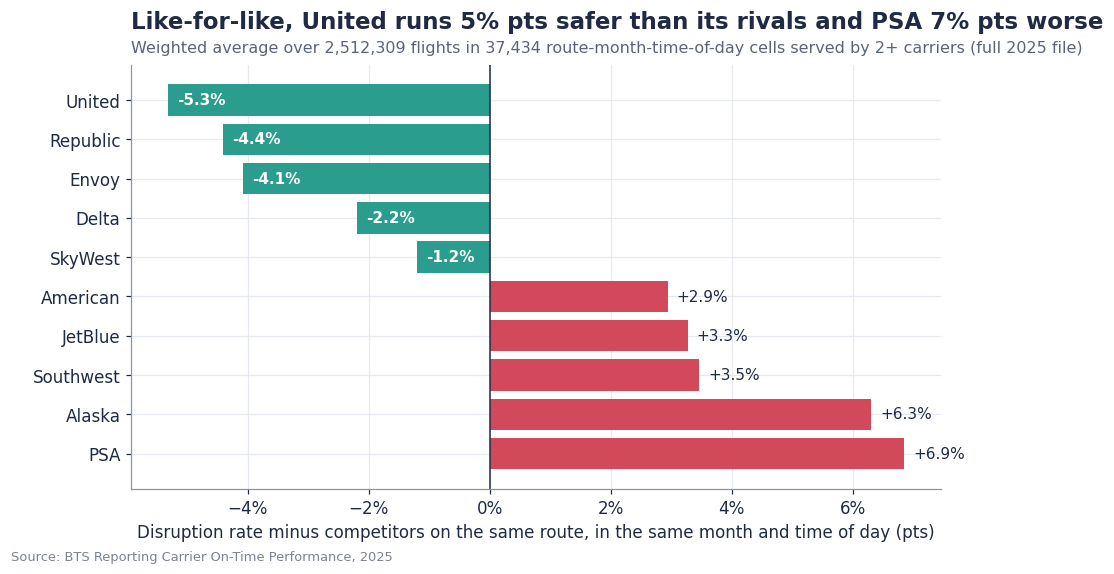

In [3]:
cell = ["route", "time_band", "MONTH"]
g = f.groupby(cell + ["CARRIER"], observed=True).agg(n=("disrupted", "size"), k=("disrupted", "sum"), ks=("severe", "sum")).reset_index()
tot = g.groupby(cell, observed=True).agg(N=("n", "sum"), K=("k", "sum"), KS=("ks", "sum"), carriers=("CARRIER", "nunique"))
g = g.merge(tot, left_on=cell, right_index=True)
g = g[(g.carriers >= 2) & (g.n >= 5) & (g.N - g.n >= 5)]
g["others"] = (g.K - g.k) / (g.N - g.n)
g["diff"] = g.k / g.n - g.others
g["sdiff"] = g.ks / g.n - (g.KS - g.ks) / (g.N - g.n)
adj = g.groupby("CARRIER", observed=True).apply(lambda d: pd.Series({"flights_compared": d.n.sum(), "adj_disrupted_vs_rivals_pts": np.average(d["diff"], weights=d.n), "adj_severe_vs_rivals_pts": np.average(d.sdiff, weights=d.n)}), include_groups=False)
adj["raw_disrupted"] = f.groupby("CARRIER", observed=True).disrupted.mean()
adj.index = adj.index.map(prep.CARRIER_NAMES)
adj = adj.sort_values("adj_disrupted_vs_rivals_pts")
adj.to_csv(prep.TABLES / "carrier_route_adjusted.csv")
fig, ax = plt.subplots(figsize=(9.5, 5))
y = np.arange(len(adj))
ax.barh(y, adj.adj_disrupted_vs_rivals_pts, color=[GOOD if v < -.01 else (ACCENT if v > .01 else GREY) for v in adj.adj_disrupted_vs_rivals_pts])
for i, v in enumerate(adj.adj_disrupted_vs_rivals_pts):
    ax.text(v + (.0015 if v >= 0 else .0015), i, f"{v:+.1%}", va="center", ha="left", fontsize=10, color="white" if v < 0 else INK, fontweight="bold" if v < 0 else None)
ax.set_yticks(y); ax.set_yticklabels(adj.index); ax.invert_yaxis(); ax.xaxis.set_major_formatter(PCT); ax.axvline(0, color=INK, lw=1)
ax.set_xlabel("Disruption rate minus competitors on the same route, in the same month and time of day (pts)")
b, w = adj.index[0], adj.index[-1]
style.titled(ax, f"Like-for-like, {b} runs {-adj.adj_disrupted_vs_rivals_pts.iloc[0]:.0%} pts safer than its rivals and {w} {adj.adj_disrupted_vs_rivals_pts.iloc[-1]:.0%} pts worse",
             f"Weighted average over {int(g.n.sum()):,} flights in {g.groupby(cell, observed=True).ngroups:,} route-month-time-of-day cells served by 2+ carriers (full 2025 file)")
style.save(fig, "14_carrier_route_adjusted");
adj

In [4]:
# Route-level preferred-carrier list: routes with 2+ carriers each flying 300+ times in 2025
rc = f.groupby(["route", "ORIGIN", "DEST", "CARRIER"], observed=True).agg(n=("disrupted", "size"), disrupted=("disrupted", "mean"), severe=("severe", "mean"), cancelled=("CANCELLED", "mean"), p90=("ARR_DELAY", lambda x: x.quantile(.9))).reset_index()
rc = rc[rc.n >= 300].copy()
rc["route"], rc["CARRIER"] = rc.route.astype(str), rc.CARRIER.astype(str)
multi = rc.groupby("route").CARRIER.transform("nunique") >= 2
rc = rc[multi].copy()
best = rc.sort_values("disrupted").groupby("route").first()
worst = rc.sort_values("disrupted").groupby("route").last()
pref = pd.DataFrame({"best_carrier": best.CARRIER.astype(str), "best_disrupted": best.disrupted, "worst_carrier": worst.CARRIER.astype(str), "worst_disrupted": worst.disrupted,
                     "route_flights": rc.groupby("route").n.sum()})
pref["gap_pts"] = pref.worst_disrupted - pref.best_disrupted
pref = pref.sort_values("route_flights", ascending=False)
pref.to_csv(prep.TABLES / "route_preferred_carrier.csv")
print(f"{len(pref)} routes with a real carrier choice. Median best-vs-worst gap {pref.gap_pts.median():.1%} pts; "
      f"{(pref.gap_pts >= .05).mean():.0%} of routes have a 5+ point gap; {(pref.gap_pts >= .10).mean():.0%} have a 10+ point gap.")
pref.head(15)

1330 routes with a real carrier choice. Median best-vs-worst gap 6.8% pts; 63% of routes have a 5+ point gap; 32% have a 10+ point gap.


,best_carrier,best_disrupted,worst_carrier,worst_disrupted,route_flights,gap_pts
route,,,,,,
LGA-ORD,YX,0.250,DL,0.355,10872,0.104
ORD-LGA,YX,0.249,AA,0.351,10870,0.102
SFO-LAX,UA,0.183,WN,0.307,10277,0.124
LAX-SFO,OO,0.234,WN,0.317,10275,0.084
JFK-LAX,AA,0.190,DL,0.231,10023,0.040
LAX-JFK,DL,0.196,AA,0.206,10020,0.010
BOS-DCA,AA,0.269,B6,0.309,9047,0.040
DCA-BOS,YX,0.249,AA,0.349,9046,0.100
PHX-DEN,UA,0.202,WN,0.285,7471,0.083


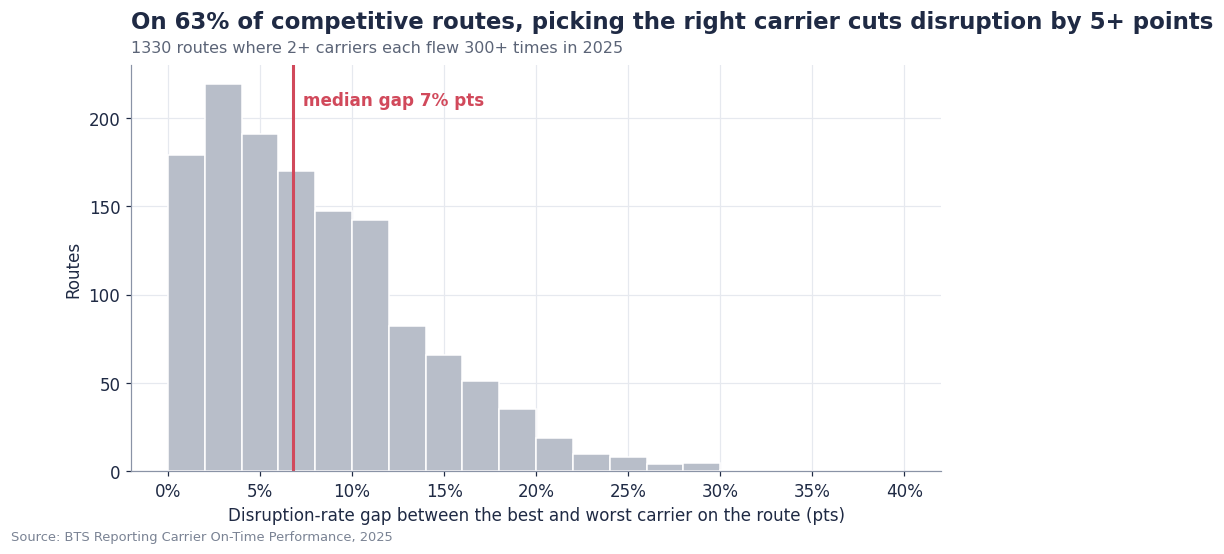

In [5]:
fig, ax = plt.subplots(figsize=(9.5, 4.8))
ax.hist(pref.gap_pts, bins=np.arange(0, .42, .02), color=GREY, edgecolor="white")
ax.axvline(pref.gap_pts.median(), color=ACCENT, lw=2); ax.text(pref.gap_pts.median() + .005, ax.get_ylim()[1] * .9, f"median gap {pref.gap_pts.median():.0%} pts", color=ACCENT, fontweight="bold")
ax.xaxis.set_major_formatter(PCT); ax.set_xlabel("Disruption-rate gap between the best and worst carrier on the route (pts)"); ax.set_ylabel("Routes")
style.titled(ax, f"On {(pref.gap_pts >= .05).mean():.0%} of competitive routes, picking the right carrier cuts disruption by 5+ points",
             f"{len(pref)} routes where 2+ carriers each flew 300+ times in 2025")
style.save(fig, "15_route_carrier_gap");

## 3. Same route, same carrier: morning vs evening

3198 route-carrier pairs with 100+ flights in both windows. Evening is worse on 98% of them; median gap 19.8% pts disrupted, 9.0% pts severe.


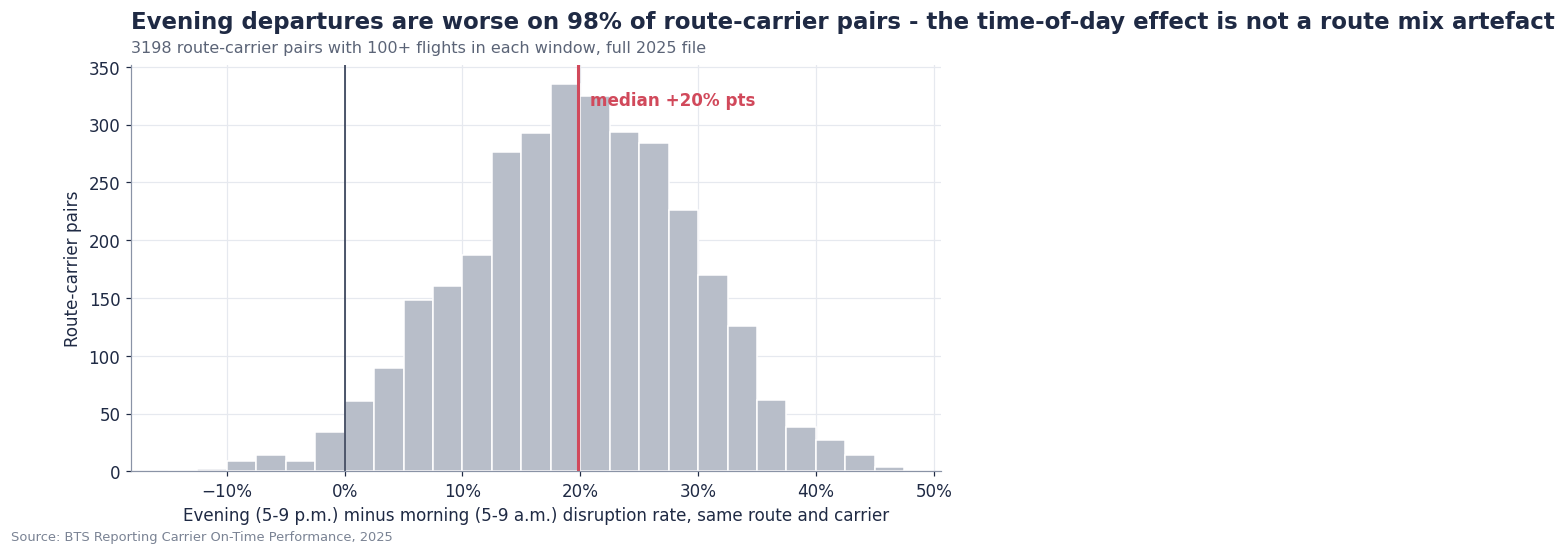

In [6]:
band = np.select([f.dep_hour.between(5, 9), f.dep_hour.between(17, 21)], ["morning", "evening"], default="other")
me = f.assign(band=band)[lambda d: d.band != "other"].groupby(["route", "CARRIER", "band"], observed=True).agg(n=("disrupted", "size"), disrupted=("disrupted", "mean"), severe=("severe", "mean")).unstack()
me = me[(me[("n", "morning")] >= 100) & (me[("n", "evening")] >= 100)]
gap = me[("disrupted", "evening")] - me[("disrupted", "morning")]
sgap = me[("severe", "evening")] - me[("severe", "morning")]
print(f"{len(me)} route-carrier pairs with 100+ flights in both windows. Evening is worse on {(gap > 0).mean():.0%} of them; "
      f"median gap {gap.median():.1%} pts disrupted, {sgap.median():.1%} pts severe.")
fig, ax = plt.subplots(figsize=(9.5, 4.8))
ax.hist(gap, bins=np.arange(-.15, .5, .025), color=GREY, edgecolor="white")
ax.axvline(0, color=INK, lw=1); ax.axvline(gap.median(), color=ACCENT, lw=2)
ax.text(gap.median() + .01, ax.get_ylim()[1] * .9, f"median +{gap.median():.0%} pts", color=ACCENT, fontweight="bold")
ax.xaxis.set_major_formatter(PCT); ax.set_xlabel("Evening (5-9 p.m.) minus morning (5-9 a.m.) disruption rate, same route and carrier"); ax.set_ylabel("Route-carrier pairs")
style.titled(ax, f"Evening departures are worse on {(gap > 0).mean():.0%} of route-carrier pairs - the time-of-day effect is not a route mix artefact",
             f"{len(me)} route-carrier pairs with 100+ flights in each window, full 2025 file")
style.save(fig, "16_same_route_morning_evening");

## 4. Lookup tables for the recommendations and the app
Route x carrier x time band x season rates, shrunk toward the route mean for thin cells
(empirical-Bayes style, prior weight = 50 flights).

In [7]:
M = 50
rt = f.groupby("route", observed=True).agg(route_n=("disrupted", "size"), route_disrupted=("disrupted", "mean"), route_severe=("severe", "mean"))
lk = f.groupby(["route", "ORIGIN", "DEST", "CARRIER", "time_band", "season"], observed=True).agg(
    n=("disrupted", "size"), disrupted=("disrupted", "mean"), severe=("severe", "mean"), cancelled=("CANCELLED", "mean"),
    p90_delay=("ARR_DELAY", lambda x: x.quantile(.9)), p95_delay=("ARR_DELAY", lambda x: x.quantile(.95)), sched_min=("CRS_ELAPSED_TIME", "median")).reset_index()
lk = lk.merge(rt, left_on="route", right_index=True)
lk["disrupted_shrunk"] = (lk.n * lk.disrupted + M * lk.route_disrupted) / (lk.n + M)
lk["severe_shrunk"] = (lk.n * lk.severe + M * lk.route_severe) / (lk.n + M)
lk.to_parquet(prep.PROCESSED / "route_lookup.parquet", index=False)
hr = f.groupby(["ORIGIN", "dep_hour"], observed=True).agg(n=("disrupted", "size"), disrupted=("disrupted", "mean"), severe=("severe", "mean"), p90_delay=("ARR_DELAY", lambda x: x.quantile(.9))).reset_index()
hr.to_parquet(prep.PROCESSED / "origin_hour_lookup.parquet", index=False)
print(len(lk), "lookup cells")
lk.head()

105386 lookup cells


,route,ORIGIN,DEST,CARRIER,time_band,season,n,disrupted,severe,cancelled,p90_delay,p95_delay,sched_min,route_n,route_disrupted,route_severe,disrupted_shrunk,severe_shrunk
0,ABE-CLT,ABE,CLT,OH,Early (5-6:59a),Fall,79,0.051,0.025,0.000,-1.400,5.350,111.000,913,0.195,0.118,0.107,0.061
1,ABE-CLT,ABE,CLT,OH,Early (5-6:59a),Spring,91,0.165,0.099,0.000,41.000,167.000,107.000,913,0.195,0.118,0.176,0.106
2,ABE-CLT,ABE,CLT,OH,Early (5-6:59a),Summer,90,0.100,0.089,0.044,2.000,16.500,105.000,913,0.195,0.118,0.134,0.099
3,ABE-CLT,ABE,CLT,OH,Early (5-6:59a),Winter,80,0.163,0.150,0.075,8.400,123.700,126.000,913,0.195,0.118,0.175,0.138
4,ABE-CLT,ABE,CLT,OH,Morning (7-9:59a),Fall,12,0.083,0.083,0.000,7.200,50.050,124.000,913,0.195,0.118,0.173,0.112


## Takeaways
* The sample reproduces the population to within its confidence intervals.
* Carrier differences survive like-for-like comparison, but the ranking changes: United, Republic
  and Envoy beat their rivals on the same route/month/time; PSA, Alaska and Southwest trail theirs.
  Alaska's raw numbers look fine only because it flies in the calm West.
* On most competitive routes the carrier choice is worth 5+ points of disruption risk.
* The morning-vs-evening gap holds for the same carrier on the same route.